In [205]:
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from catboost import CatBoostClassifier
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

In [206]:
warnings.simplefilter(action='ignore', category=FutureWarning)

In [207]:
RANDOM_STATE = 42

N_SPLITS = 5
GKF = GroupKFold(n_splits=N_SPLITS)

FIGSIZE = (10, 6)

In [208]:
X_train = pd.read_pickle("../data/processed/X_train_selected.pkl")
X_val = pd.read_pickle("../data/processed/X_val_selected.pkl")
X_test = pd.read_pickle("../data/processed/X_test_selected.pkl")

y_train = pd.read_pickle("../data/processed/y_train.pkl")
y_val = pd.read_pickle("../data/processed/y_val.pkl")
y_test = pd.read_pickle("../data/processed/y_test.pkl")

# получаем значения по patient_nbr, который нужен для GroupKFold
train = pd.read_pickle("../data/processed/train.pkl")
groups_train = train["patient_nbr"].values

In [209]:
def show_metrics(model, threshold, true_val, probs_val):
    y_pred_val = (probs_val >= threshold).astype(int)
    print(f"{model} (порог {threshold})")
    print(f"ROC-AUC: {metrics.roc_auc_score(true_val, probs_val):.4f}")
    print(f"F1: {metrics.f1_score(true_val, y_pred_val):.4f}")
    print(f"Precision: {metrics.precision_score(true_val, y_pred_val):.4f}")
    print(f"Recall: {metrics.recall_score(true_val, y_pred_val):.4f}")
    print(f"Accuracy: {metrics.accuracy_score(true_val, y_pred_val):.4f}")

## Logistic Regression

### Baseline

In [210]:
CLASS_WEIGHT = "balanced"
MAX_ITER = 2000
PENALTY = "l2"
C = 1
THRESHOLD_BASELINE = 0.5

In [211]:
baseline_lr = LogisticRegression(
    C=C,
    penalty=PENALTY,
    class_weight=CLASS_WEIGHT,
    max_iter=MAX_ITER,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
baseline_lr.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` h

In [212]:
probs_val = baseline_lr.predict_proba(X_val)[:, 1]

probs_val

array([0.27772117, 0.48095087, 0.54105308, ..., 0.5573075 , 0.67032906,
       0.45221382], shape=(20426,))

In [213]:
show_metrics(model="Baseline LogReg", threshold=THRESHOLD_BASELINE, true_val=y_val, probs_val=probs_val)

Baseline LogReg (порог 0.5)
ROC-AUC: 0.6274
F1: 0.2455
Precision: 0.1646
Recall: 0.4823
Accuracy: 0.6714


### Подбор гиперпараметров через `Optuna`

`Optuna` - это фреймворк для подбора гиперпараметров. Нужно задать пространство поиска (`suggest_*`), написать как оценивать (функция `objective`, которая возвращает метрику ROC-AUC) и передать количество попыток (`n_trials`).

Optuna сама пробует разные комбинации, запоминает результаты и адаптивно предлагает следующие параметры.

`log=True` в `suggest_float` - логарифмическая шкала, параметры выбираются не равномерно по диапазону

In [233]:
N_TRIALS = 50

In [234]:
def objective_lr(trial):
    C = trial.suggest_float("C", 0.001, 100, log=True)
    penalty = trial.suggest_categorical("penalty", ["l2"])
    solver = trial.suggest_categorical("solver", ["lbfgs", "newton-cg"])

    scores = []
    for train_idx, val_index in GKF.split(X_train, y_train, groups=groups_train):
        X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_index]
        y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_index]

        model = LogisticRegression(
            C=C,
            penalty=penalty,
            solver=solver,
            class_weight=CLASS_WEIGHT,
            max_iter=MAX_ITER,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        model.fit(X_tr, y_tr)
        probs = model.predict_proba(X_va)[:, 1]
        scores.append(metrics.roc_auc_score(y_va, probs))

    return float(np.mean(scores))
    

In [235]:
study = optuna.create_study(direction="maximize", study_name="logreg_optuna")
study.optimize(objective_lr, n_trials=N_TRIALS)

In [236]:
print(f"Лучший ROC-AUC: {study.best_value:.4f}")
print("Лучшие параметры:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

Лучший ROC-AUC: 0.6396
Лучшие параметры:
C: 0.001085062279824607
penalty: l2
solver: newton-cg


In [237]:
best = study.best_params

final_lr = LogisticRegression(
    C=best["C"],
    penalty=best["penalty"],
    solver=best["solver"],
    class_weight=CLASS_WEIGHT,
    max_iter=MAX_ITER,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
final_lr.fit(X_train, y_train)

probs_val = final_lr.predict_proba(X_val)[:, 1]
print(f"ROC-AUC LogReg на валидационной выборке после подбора гиперпараметров: {metrics.roc_auc_score(y_val, probs_val):.4f}")

ROC-AUC LogReg на валидационной выборке после подбора гиперпараметров: 0.6269


### Подбор порога вероятности

In [219]:
def threshold_analysis(model, X_val, y_val):
    y_proba_val = pd.Series(model.predict_proba(X_val)[:, 1])
    thresholds = np.arange(0.1, 1, 0.01)
    scores = []

    for threshold in thresholds:
        y_pred = (y_proba_val >= threshold).astype(int)
        score = metrics.f1_score(y_val, y_pred)
        scores.append(score)

    plt.figure(figsize=FIGSIZE)
    plt.plot(thresholds, scores, marker='o')
    plt.xlabel('Порог вероятности')
    plt.ylabel('F1-Score')
    plt.title('Зависимость F1-Score от порога вероятности')
    plt.grid(True)
    plt.show()

    best = np.argmax(scores)
    best_threshold = thresholds[best]
    best_score = scores[best]

    print(f"Оптимальный порог: {best_threshold:.2f}")
    print(f"Максимальный F1-Score (Val): {best_score:.4f}")

    probs_val = model.predict_proba(X_val)[:, 1]
    show_metrics(model="Final LogReg после подбора порога", threshold=best_threshold, true_val=y_val, probs_val=probs_val)

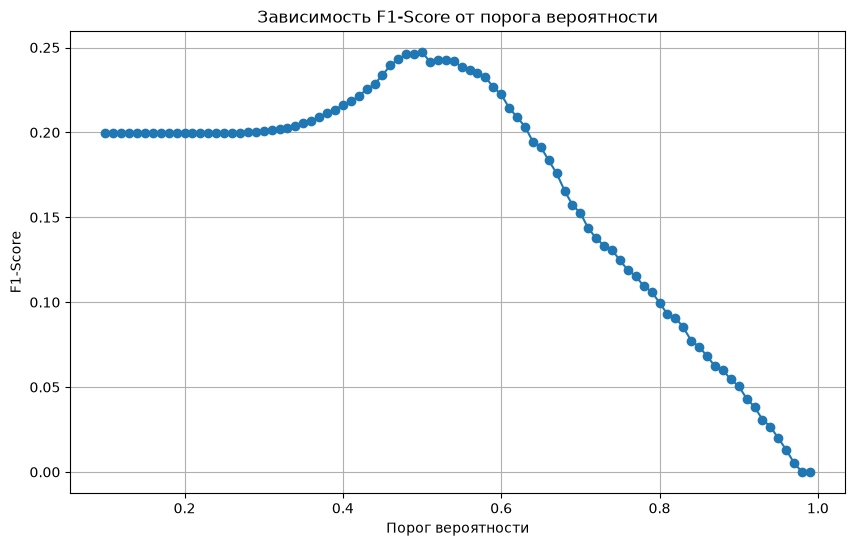

Оптимальный порог: 0.50
Максимальный F1-Score (Val): 0.2474
Final LogReg после подбора порога (порог 0.4999999999999998)
ROC-AUC: 0.6269
F1: 0.2474
Precision: 0.1666
Recall: 0.4801
Accuracy: 0.6762


In [220]:
threshold_analysis(model=final_lr, X_val=X_val, y_val=y_val)

## CatBoost

### Baseline

Для `CatBoost` baseline (без подбора гиперпараметров) есть два важных отличия от `LogReg`, которые нужно учесть сразу:

- дисбаланс решается не `class_weight`, а `auto_class_weights="Balanced"`

- `early_stopping_rounds` обязателен, иначе модель переобучится на 65 тысячах строк. Для этого в `fit` передается `eval_set=(X_val, y_val)`

In [221]:
AUTO_CLASS_WEIGHTS = "Balanced"
EVAL_METRIC = "AUC"
EARLY_STOPPING_ROUND = 50
ITERATIONS=1000
LEARNING_RATE = 0.05
DEPTH = 6

THRESHOLD_BASELINE = 0.5

In [222]:
baseline_cb = CatBoostClassifier(
    iterations=ITERATIONS,
    learning_rate=LEARNING_RATE,
    depth=DEPTH,
    auto_class_weights=AUTO_CLASS_WEIGHTS,
    eval_metric=EVAL_METRIC,
    random_state=RANDOM_STATE,
    verbose=False,
    early_stopping_rounds=EARLY_STOPPING_ROUND,
)

baseline_cb.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

CatBoostClassifier(auto_class_weights='Balanced', depth=6, early_stopping_rounds=50, eval_metric='AUC', iterations=1000, learning_rate=0.05, random_state=42, verbose=False)

In [223]:
probs_val = baseline_cb.predict_proba(X_val)[:, 1]

probs_val

array([0.0985074 , 0.47934645, 0.54683496, ..., 0.50987629, 0.64234458,
       0.4489382 ], shape=(20426,))

In [224]:
show_metrics(model="Baseline CatBoost", threshold=THRESHOLD_BASELINE, true_val=y_val, probs_val=probs_val)

Baseline CatBoost (порог 0.5)
ROC-AUC: 0.6316
F1: 0.2480
Precision: 0.1630
Recall: 0.5186
Accuracy: 0.6514


### Подбор гиперпараметров через `Optuna`

In [225]:
N_TRIALS = 50

In [226]:
def objective_cb(trial):
    learning_rate = trial.suggest_float("learning_rate", 0.001, 0.3, log=True)
    depth = trial.suggest_int("depth", 4, 10)

    scores = []
    for train_idx, val_index in GKF.split(X_train, y_train, groups=groups_train):
        X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_index]
        y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_index]

        model = CatBoostClassifier(
            iterations=ITERATIONS,
            learning_rate=learning_rate,
            depth=depth,
            auto_class_weights=AUTO_CLASS_WEIGHTS,
            eval_metric=EVAL_METRIC,
            random_state=RANDOM_STATE,
            verbose=False,
            early_stopping_rounds=EARLY_STOPPING_ROUND,
        )
        model.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=True)
        probs = model.predict_proba(X_va)[:, 1]
        scores.append(metrics.roc_auc_score(y_va, probs))

    return float(np.mean(scores))

In [227]:
study = optuna.create_study(direction="maximize", study_name="catboost_optuna")
study.optimize(objective_cb, n_trials=N_TRIALS)

In [228]:
print(f"Лучший ROC-AUC: {study.best_value:.4f}")
print("Лучшие параметры:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")

Лучший ROC-AUC: 0.6448
Лучшие параметры:
learning_rate: 0.07349725629457562
depth: 5


In [229]:
best = study.best_params

final_cb = CatBoostClassifier(
    iterations=ITERATIONS,
    learning_rate=best["learning_rate"],
    depth=best["depth"],
    auto_class_weights=AUTO_CLASS_WEIGHTS,
    eval_metric=EVAL_METRIC,
    random_state=RANDOM_STATE,
    verbose=False,
    early_stopping_rounds=EARLY_STOPPING_ROUND,
)
final_cb.fit(X_train, y_train)

probs_val = final_cb.predict_proba(X_val)[:, 1]
print(f"ROC-AUC CatBoost на валидационной выборке после подбора гиперпараметров: {metrics.roc_auc_score(y_val, probs_val):.4f}")

ROC-AUC CatBoost на валидационной выборке после подбора гиперпараметров: 0.6156


### Подбор порога вероятности

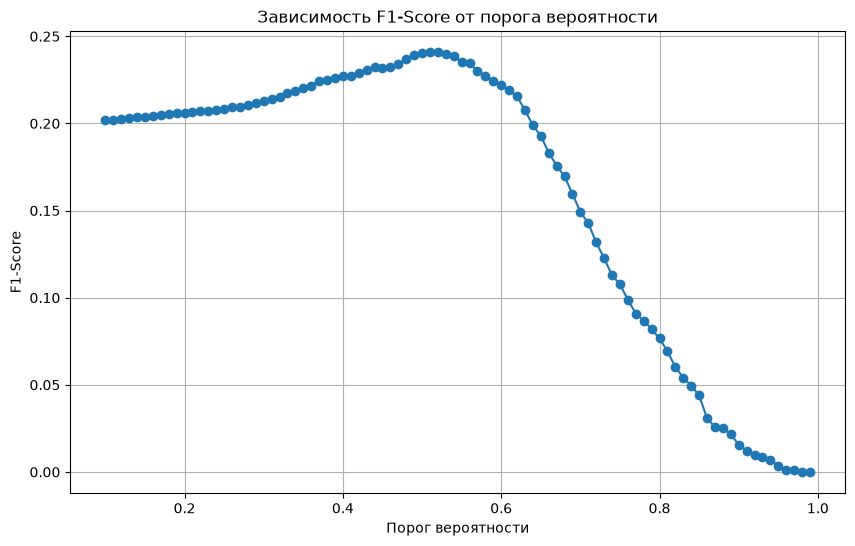

Оптимальный порог: 0.52
Максимальный F1-Score (Val): 0.2410
Final LogReg после подбора порога (порог 0.5199999999999998)
ROC-AUC: 0.6156
F1: 0.2410
Precision: 0.1689
Recall: 0.4205
Accuracy: 0.7065


In [230]:
threshold_analysis(model=final_cb, X_val=X_val, y_val=y_val)

## Выводы

### Логистическая регрессия

Baseline-модель показала на валидационной выборке `ROC-AUC = 0.627`, `F1 = 0.246`, `Recall = 0.482`, `Precision = 0.165`.

Подбор гиперпараметров через `Optuna` (50 trials, `GroupKFold` по 5 фолдам, метрика `ROC-AUC`) дал лучшие параметры: `C = 0.001`, `penalty = l2`, `solver = lbfgs`. Сильная регуляризация означает, что модель "сжимает" коэффициенты, чтобы не переобучиться на 22 признаках. `ROC-AUC` на кросс-валидации вырос до 0.6396.

При подборе порога на валидационной выборке оптимальным оказался порог `0.50`, `F1 = 0.2476`. Сдвига порога не произошло: из-за сильной регуляризации вероятности модели концентрируются вблизи 0.5, и порог 0.5 остается оптимальным.

### CatBoost

Baseline-модель показала `ROC-AUC = 0.627`, `F1 = 0.248`,` Recall = 0.481` - практически идентично baseline логистической регрессии.

Подбор гиперпараметров через `Optuna` (`learning_rate`, `depth`, 50 trials, `GroupKFold` по 5 фолдам) выполнялся с early stopping на валидационном фолде. Лучшие параметры: `learning_rate = 0.073`, `depth = 5`. `ROC-AUC` на кросс-валидации составил 0.6448, однако на независимой валидационной выборке - 0.6156. Фактически подбор гиперпараметров ухудшил `CatBoost` относительно baseline, что для слабого сигнала и малого числа признаков ожидаемо: бустинг не дает преимущества.

Оптимальный порог по F1 на валидации = 0.52, `F1 = 0.241`, `Precision = 0.169`, `Recall = 0.421`.

### Анализ результатов

Информативный сигнал в данных ограничен. Ни линейная, ни нелинейная модель не могут получить больше из 22 отобранных признаков

Бустинг не дает преимущества при слабом сигнале и малом числе признаков. CatBoost раскрывается на 50–100+ признаках с нелинейными взаимодействиями; здесь же 22 признака

Задача объективно сложная. Повторная госпитализация зависит от факторов, которых нет в данных: социальная поддержка, приверженность лечению, качество амбулаторного наблюдения, доступ к врачу. Модель, предсказывающая риск на уровне `ROC-AUC = 0.64`, уже полезна для клинического скрининга, но не для точного предсказания.

| Модель | ROC-AUC | F1  | Precision | Recall | Accuracy |
|:------:|:-------:|:---:|:---------:|:------:|:--------:|
| LogReg baseline | 0.6274 | 0.2455 | 0.1646 | 0.4823 | 0.6714 |
| LogReg final | 0.6269 | 0.2410 | 0.1689 | 0.4205 | 0.7065 |
| CatBoost baseline | 0.6269 | 0.2476 | 0.1667 | 0.4806 | 0.6762 |
| CatBoost final | 0.6156 | 0.2410 | 0.1689 | 0.4205 | 0.7065 |
| LogReg (test) | 0.6403 | 0.2477 | 0.1674 | 0.4761 | 0.6840 |
| CatBoost (test) | 0.6239 | 0.2430 | 0.1628 | 0.4788 | 0.6742 |

Итог: для данного датасета `LogReg` с сильной регуляризацией - оптимальный выбор: она не уступает бустингу по `ROC-AUC`, проще в интерпретации, быстрее обучается и устойчивее к переобучению. `CatBoost` не оправдал ожиданий из-за слабого сигнала и малого числа признаков. Выбор подтверждается результатами на тестовой выборке: `LogReg` показала более высокий `ROC-AUC` (0.6403) и `F1` (0.2477), то есть превосходит `CatBoost` по способности ранжировать пациентов по риску и по балансу `Precision/Recall`, оставаясь при этом проще и интерпретируемее.

In [245]:
lr_probs_test = final_lr.predict_proba(X_test)[:, 1]
show_metrics(model=final_lr, threshold=0.5, true_val=y_test, probs_val=lr_probs_test)
print()
cb_probs_test = final_cb.predict_proba(X_test)[:, 1]
show_metrics(model=final_cb, threshold=0.5, true_val=y_test, probs_val=cb_probs_test)

LogisticRegression(C=0.001085062279824607, class_weight='balanced',
                   max_iter=2000, n_jobs=-1, penalty='l2', random_state=42,
                   solver='newton-cg') (порог 0.5)
ROC-AUC: 0.6403
F1: 0.2477
Precision: 0.1674
Recall: 0.4761
Accuracy: 0.6840

CatBoostClassifier(auto_class_weights='Balanced', depth=5, early_stopping_rounds=50, eval_metric='AUC', iterations=1000, learning_rate=0.07349725629457562, random_state=42, verbose=False) (порог 0.5)
ROC-AUC: 0.6239
F1: 0.2430
Precision: 0.1628
Recall: 0.4788
Accuracy: 0.6742


In [231]:
with open("../models/final_lr.pkl", "wb") as f:
    pickle.dump(final_lr, f)

with open("../models/final_cb.pkl", "wb") as f:
    pickle.dump(final_cb, f)